# Transit Job Accessibility Analysis in the DART Region

**Research question:** How accessible are jobs via DART for transit-dependent
neighborhoods in the Dallas–Fort Worth metroplex?

**Study area:** All DART service counties: Dallas, Collin, Denton, Rockwall, Ellis
**Focus:** Low-income / carless (transit-dependent) households

**Data (all 2023 except GTFS, which is the current DART feed):**
- GTFS — DART transit schedules
- LODES (WAC) — employment by census block
- ACS B19013 — median household income by tract
- ACS B08201 — vehicle availability by tract
- TIGER/Line — census tract boundaries

In [1]:
# imports
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as cx
from shapely.ops import polygonize, unary_union

# r5py for transit routing / isochrones (requires Java 21)
from r5py import TransportNetwork, Isochrones, TransportMode
import datetime

print("All packages imported successfully.")

All packages imported successfully.


## 1. load census tracts and filter to the DART service area

We load the Texas census-tract shapefile and keep only the five DART counties:
Dallas (113), Collin (085), Denton (121), Rockwall (397), and Ellis (139)

In [3]:
# 1. load census tracts + filter to dart counties
tracts = gpd.read_file("shapefiles/tl_2025_48_tract.shp")
tracts["GEOID"] = tracts["GEOID"].astype(str)   # keep GEOID as text for joining

# DART service-area counties (by county FIPS code)
dart_counties = ["113", "085", "121", "397", "139"]  # Dallas, Collin, Denton, Rockwall, Ellis
dart = tracts[tracts["COUNTYFP"].isin(dart_counties)].copy()

print(f"Census tracts in DART region: {len(dart)}")

Census tracts in DART region: 1123


## 2. Load and clean median household income (ACS B19013, 2023)

The raw ACS file has an extra header row and stores the tract ID in a long format
(e.g. `1400000US48113000100`), so we extract the real GEOID and convert income to a number.

In [4]:
# 2. load + clean income data (ACS B19013)
# skiprows=[1] drops the ACS descriptive second header row
income = pd.read_csv("census/income_2023.csv", skiprows=[1])

# the GEOID looks like "1400000US48113000100" - the real GEOID is after "US"
income["GEOID"] = income["GEO_ID"].str.split("US").str[1]

# keep only what we need and give the income column a clear name
income = income[["GEOID", "B19013_001E"]].rename(columns={"B19013_001E": "median_income"})

# convert income to numeric ("-" or blank cells become NaN)
income["median_income"] = pd.to_numeric(income["median_income"], errors="coerce")

# join income onto the DART tracts
dart = dart.merge(income, on="GEOID", how="left")

print(f"Tracts with income data: {dart['median_income'].notna().sum()} / {len(dart)}")

Tracts with income data: 1101 / 1123


## 3. Load employment data (LODES WAC, 2023)

LODES reports jobs at the census-block level. Since the first 11 digits of a
15-digit block code are the tract GEOID, we roll block-level jobs up to the tract
level, then join onto the DART tracts.

In [5]:
# 3. load employment data (LODES WAC) + roll up to tracts
# pandas reads the compressed .gz file directly
lodes = pd.read_csv("lodes/tx_wac_S000_JT00_2023.csv.gz")

# Block code is 15 digits; the first 11 are the tract GEOID
lodes["GEOID"] = lodes["w_geocode"].astype(str).str.zfill(15).str[:11]

# Sum all block-level jobs (C000 = total jobs) within each tract
jobs_by_tract = (
    lodes.groupby("GEOID")["C000"].sum().reset_index()
    .rename(columns={"C000": "total_jobs"})
)

# Join jobs onto the DART tracts
dart = dart.merge(jobs_by_tract, on="GEOID", how="left")

print(f"Total jobs across DART region: {dart['total_jobs'].sum():,.0f}")

Total jobs across DART region: 2,905,949


## 4. Map income and jobs (with basemaps)

We reproject to Web Mercator (EPSG:3857) so the Contextily basemap tiles align,
then plot income and jobs as choropleth maps over a real map of the metroplex.

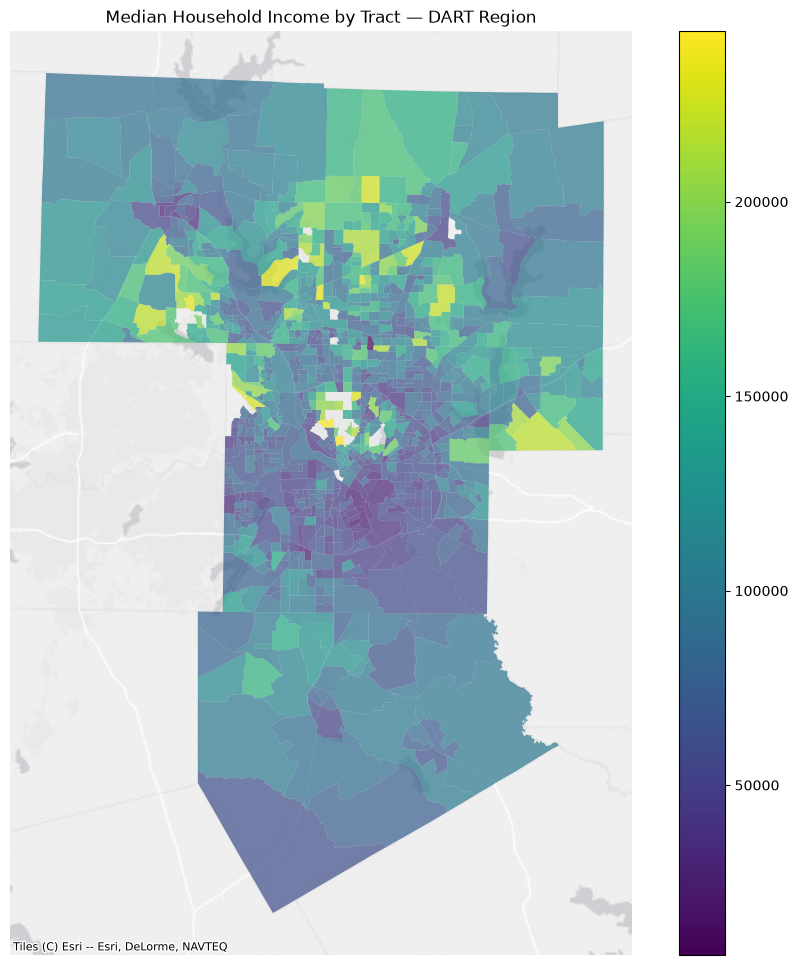

In [6]:
# 4a. income map (with basemap)
# reproject to web mercator so basemap tiles line up
dart_web = dart.to_crs(epsg=3857)

fig, ax = plt.subplots(figsize=(12, 12))
dart_web.plot(column="median_income", ax=ax, legend=True, alpha=0.7, cmap="viridis")
cx.add_basemap(ax, source=cx.providers.Esri.WorldGrayCanvas)
ax.set_title("Median Household Income by Tract — DART Region")
ax.set_axis_off()
plt.show()

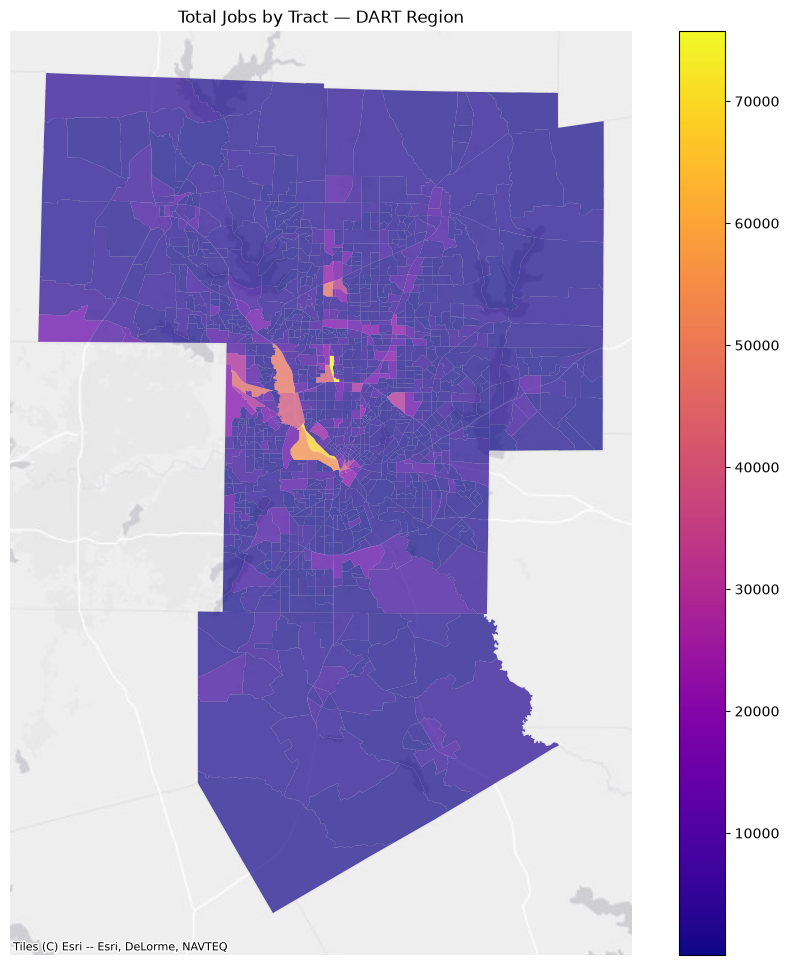

In [12]:

# 4b. jobs map (with basemap)
fig, ax = plt.subplots(figsize=(12, 12))
dart_web.plot(column="total_jobs", ax=ax, legend=True, alpha=0.7, cmap="plasma")
cx.add_basemap(ax, source=cx.providers.Esri.WorldGrayCanvas)
ax.set_title("Total Jobs by Tract — DART Region")
ax.set_axis_off()
plt.show()

## 5. Build the transport network (r5py)

We build a combined street + transit network from the DFW OpenStreetMap extract
and the DART GTFS feed. This is what r5py uses to compute travel times.

*Note: the OSM file was cropped to the DFW area because the full Texas extract
exceeds r5py's size limit. `allow_errors=True` skips a non-critical GTFS fare
formatting issue that doesn't affect travel-time routing.*

In [13]:
# 5. build transport network (streets + transit)
# osm/dfw.osm.pbf = DFW-cropped street network
# gtfs/google_transit.zip = DART transit schedules
print("Building transport network (this can take a few minutes)...")
network = TransportNetwork(
    "osm/dfw.osm.pbf",
    ["gtfs/google_transit.zip"],
    allow_errors=True   # skip non-critical GTFS fare validation issues
)
print("Network built!")

Building transport network (this can take a few minutes)...


java.io.IOError: java.io.IOError: java.io.IOException: Wrong index checksum, store was not closed properly and could be corrupted.

## 6. Compute tract centroids

For each tract we need a single origin point. We reproject to EPSG:3083
(a Texas-centric projection in meters) for accurate centroids, then convert
those centroids back to lat/lon (EPSG:4326) for use with r5py.

In [14]:

# 6. tract centroids (origins for isochrones)
# EPSG:3083 is in meters -> accurate centroids (EPSG:4326 degrees would distort)
dart_projected = dart.to_crs("epsg:3083")
dart_projected["centroid"] = dart_projected.geometry.centroid

# build a GeoDataFrame of centroids, projected back to lat/lon for r5py
centroids = dart_projected[["GEOID"]].copy()
centroids = gpd.GeoDataFrame(
    centroids,
    geometry=dart_projected["centroid"],
    crs="epsg:3083"
).to_crs("epsg:4326")

print(f"Centroids ready: {len(centroids)} tracts")
print(centroids.head(3))

Centroids ready: 1123 tracts
         GEOID                    geometry
0  48113017819  POINT (-96.63241 32.81649)
1  48113005400  POINT (-96.81744 32.72731)
2  48113005500  POINT (-96.79954 32.72518)


## 7. Compute transit isochrones from each tract

For each tract centroid, we compute the area reachable within 45 minutes by
transit + walking (departing 8:30 AM on a weekday). Job counts inside each
isochrone give a "jobs reachable by transit" measure per tract.

sample test down below

In [12]:

# 7. isochrone loop (sample shown; full run -> HPC)
# set to `centroids` for the full run (slow); a small sample here for demonstration
origins_to_run = centroids.head(5)

results = []
for idx, row in origins_to_run.iterrows():
    origin = gpd.GeoDataFrame(
        {"id": [row["GEOID"]]},
        geometry=[row.geometry],
        crs="EPSG:4326"
    )
    iso = Isochrones(
        network,
        origins=origin,
        departure=datetime.datetime(2026, 6, 12, 8, 30),   # weekday, morning peak
        isochrones=[datetime.timedelta(minutes=45)],
        transport_modes=[TransportMode.TRANSIT, TransportMode.WALK],
    )
    iso["GEOID"] = row["GEOID"]      # tag each isochrone with its origin tract
    results.append(iso)

# combine into one GeoDataFrame
all_isochrones = gpd.GeoDataFrame(pd.concat(results, ignore_index=True), crs="EPSG:4326")

# convert the travel_time duration to plain minutes (GeoPackage can't store timedelta)
all_isochrones["minutes"] = all_isochrones["travel_time"].dt.total_seconds() / 60
all_isochrones = all_isochrones.drop(columns=["travel_time"])

# save so the (slow) results can be reloaded without recomputing
all_isochrones.to_file("sample_isochrones.gpkg", driver="GPKG")

## 8. Count jobs reachable by transit

r5py returns isochrones as boundary lines, so we first fill them into polygons.
Then we place each tract's jobs at its centroid and use a spatial join to count
how many jobs fall inside each isochrone — i.e. jobs reachable within 45 minutes.

In [13]:

# 8. count jobs reachable by transit
# r5py returns MultiLineString rings; fill them into solid polygons
# (a point can't fall "inside" a line, only a polygon)
filled = []
for idx, row in all_isochrones.iterrows():
    polys = list(polygonize(row.geometry))
    filled.append(unary_union(polys) if polys else None)

iso_filled = all_isochrones.copy()
iso_filled["geometry"] = filled
iso_filled = gpd.GeoDataFrame(iso_filled[iso_filled.geometry.notna()], crs="EPSG:4326")

# job points = tract centroids carrying that tract's job count
job_points = centroids.merge(dart[["GEOID", "total_jobs"]], on="GEOID", how="left")

# spatial join: which job points fall inside each isochrone?
reachable = gpd.sjoin(job_points, iso_filled, how="inner", predicate="within")

# Ssum jobs reachable from each origin tract
jobs_reachable = (
    reachable.groupby("GEOID_right")["total_jobs"].sum().reset_index()
    .rename(columns={"GEOID_right": "GEOID", "total_jobs": "jobs_reachable_45min"})
)

print(jobs_reachable)

         GEOID  jobs_reachable_45min
0  48113005300                 74245
1  48113005400                117006
2  48113005500                 29917
3  48113005600                 65850
4  48113017819                 13674


## 9. Combine accessibility with income

We merge the "jobs reachable" measure back onto the tract data (which has income)
so we can compare transit job access against income

In [10]:

# 9. combine accesibility with income
# merge jobs-reachable back onto the tract data (which already has income)
result = dart.merge(jobs_reachable, on="GEOID", how="left")

# preview tracts that have an accessibility result
summary = result[["GEOID", "median_income", "total_jobs", "jobs_reachable_45min"]]
print(summary.dropna(subset=["jobs_reachable_45min"]))

# on the full dataset, this correlation is the comparison
valid = result.dropna(subset=["median_income", "jobs_reachable_45min"])
if len(valid) > 2:
    corr = valid["median_income"].corr(valid["jobs_reachable_45min"])
    print(f"\nIncome vs. jobs reachable — correlation: {corr:.3f} (n={len(valid)})")

NameError: name 'jobs_reachable' is not defined

In [15]:
import geopandas as gpd

# load the full DFW isochrones from prof michels
iso_full = gpd.read_file("Isochrones-DFW.gpkg")


print(f"Number of rows: {len(iso_full)}")
print(f"Columns: {iso_full.columns.tolist()}")
print(f"CRS: {iso_full.crs}")
print("\nFirst few rows:")
print(iso_full.head())


Number of rows: 6738
Columns: ['GEOID', 'minutes', 'geometry']
CRS: EPSG:4326

First few rows:
         GEOID  minutes                                           geometry
0  48113016415     10.0  MULTILINESTRING ((-96.77143 32.89531, -96.7730...
1  48113016415     15.0  MULTILINESTRING ((-96.7796 32.89642, -96.77931...
2  48113016415     20.0  MULTILINESTRING ((-96.78103 32.89859, -96.7793...
3  48113016415     30.0  MULTILINESTRING ((-96.75572 32.86709, -96.7555...
4  48113016415     45.0  MULTILINESTRING ((-96.70281 33.00105, -96.7028...


In [16]:
from shapely.ops import polygonize, unary_union

# filter to the 45-minute isochrones only
iso_45 = iso_full[iso_full["minutes"] == 45.0].copy()
print(f"45-minute isochrones: {len(iso_45)} tracts")

# fill the line-rings into solid polygons
filled = []
for idx, row in iso_45.iterrows():
    polys = list(polygonize(row.geometry))
    filled.append(unary_union(polys) if polys else None)

iso_45["geometry"] = filled
iso_45 = gpd.GeoDataFrame(iso_45[iso_45.geometry.notna()], crs="EPSG:4326")
print(f"Successfully filled: {len(iso_45)} polygons")

45-minute isochrones: 1123 tracts
Successfully filled: 1123 polygons


In [17]:
# job points = tract centroids carrying each tract's job count
job_points = centroids.merge(dart[["GEOID", "total_jobs"]], on="GEOID", how="left")

# spatial join: which job points fall inside each tract's 45-min isochrone?
reachable = gpd.sjoin(job_points, iso_45, how="inner", predicate="within")

# sum jobs reachable from each origin tract
jobs_reachable = (
    reachable.groupby("GEOID_right")["total_jobs"].sum().reset_index()
    .rename(columns={"GEOID_right": "GEOID", "total_jobs": "jobs_reachable_45min"})
)

print(f"Tracts with an accessibility score: {len(jobs_reachable)}")
print(jobs_reachable["jobs_reachable_45min"].describe())

Tracts with an accessibility score: 1123
count    1.123000e+03
mean     6.952376e+05
std      3.490155e+05
min      3.867000e+04
25%      4.330880e+05
50%      7.049280e+05
75%      9.094515e+05
max      1.528569e+06
Name: jobs_reachable_45min, dtype: float64


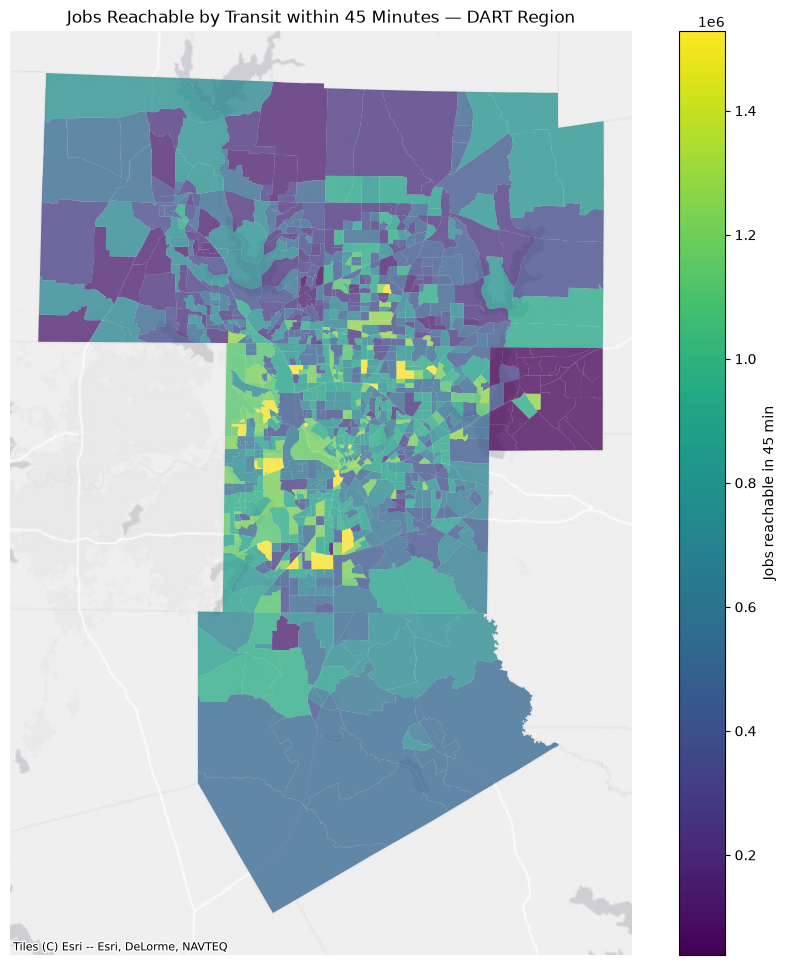

In [18]:
import contextily as cx
import matplotlib.pyplot as plt

# attach the accessibility scores back onto the tract shapes
access_map = dart.merge(jobs_reachable, on="GEOID", how="left")

# reproject for basemap
access_web = access_map.to_crs(epsg=3857)

# plot: each tract colored by jobs reachable in 45 min
fig, ax = plt.subplots(figsize=(12, 12))
access_web.plot(
    column="jobs_reachable_45min",
    ax=ax,
    legend=True,
    alpha=0.75,
    cmap="viridis",
    legend_kwds={"label": "Jobs reachable in 45 min"}
)
cx.add_basemap(ax, source=cx.providers.Esri.WorldGrayCanvas)

ax.set_title("Jobs Reachable by Transit within 45 Minutes — DART Region")
ax.set_axis_off()
plt.savefig("figures/accessibility_map.png", dpi=300, bbox_inches="tight")

plt.show()

Correlation between income and job access: -0.242
Number of tracts analyzed: 1101


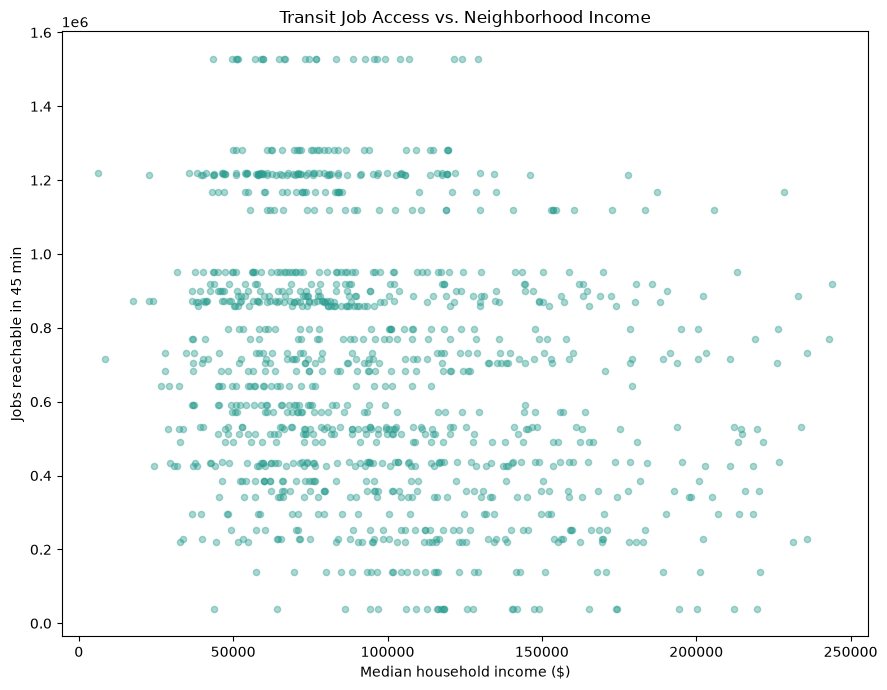

In [19]:
import matplotlib.pyplot as plt

# combining access & income (since htey both are already on access_map)
analysis = access_map.dropna(subset=["median_income", "jobs_reachable_45min"]).copy()

# correlation
corr = analysis["median_income"].corr(analysis["jobs_reachable_45min"])
print(f"Correlation between income and job access: {corr:.3f}")
print(f"Number of tracts analyzed: {len(analysis)}")

# scatterplot
fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(analysis["median_income"], analysis["jobs_reachable_45min"],
           alpha=0.4, s=20, color="#2A9D8F")
ax.set_xlabel("Median household income ($)")
ax.set_ylabel("Jobs reachable in 45 min")
ax.set_title("Transit Job Access vs. Neighborhood Income")
plt.tight_layout()
plt.savefig("figures/access_vs_income.png", dpi=300, bbox_inches="tight")

plt.show()

In [20]:
import pandas as pd

# loading the vehicle availability data (B08201)
vehicles = pd.read_csv("census/carOwnership_2023.csv", skiprows=[1])
print(f"Shape: {vehicles.shape}")
print(f"\nColumns: {vehicles.columns.tolist()}")
print(f"\nFirst 2 rows:")
print(vehicles.head(2))

Shape: (1123, 63)

Columns: ['GEO_ID', 'NAME', 'B08201_001E', 'B08201_001M', 'B08201_002E', 'B08201_002M', 'B08201_003E', 'B08201_003M', 'B08201_004E', 'B08201_004M', 'B08201_005E', 'B08201_005M', 'B08201_006E', 'B08201_006M', 'B08201_007E', 'B08201_007M', 'B08201_008E', 'B08201_008M', 'B08201_009E', 'B08201_009M', 'B08201_010E', 'B08201_010M', 'B08201_011E', 'B08201_011M', 'B08201_012E', 'B08201_012M', 'B08201_013E', 'B08201_013M', 'B08201_014E', 'B08201_014M', 'B08201_015E', 'B08201_015M', 'B08201_016E', 'B08201_016M', 'B08201_017E', 'B08201_017M', 'B08201_018E', 'B08201_018M', 'B08201_019E', 'B08201_019M', 'B08201_020E', 'B08201_020M', 'B08201_021E', 'B08201_021M', 'B08201_022E', 'B08201_022M', 'B08201_023E', 'B08201_023M', 'B08201_024E', 'B08201_024M', 'B08201_025E', 'B08201_025M', 'B08201_026E', 'B08201_026M', 'B08201_027E', 'B08201_027M', 'B08201_028E', 'B08201_028M', 'B08201_029E', 'B08201_029M', 'B08201_030E', 'B08201_030M', 'Unnamed: 62']

First 2 rows:
                 GEO_ID

In [21]:
vehicles["GEOID"] = vehicles["GEO_ID"].str.split("US").str[1]
vehicles["total_households"] = pd.to_numeric(vehicles["B08201_001E"], errors="coerce")
vehicles["zero_vehicle_households"] = pd.to_numeric(vehicles["B08201_002E"], errors="coerce")

# calculate percent of households with no vehicle
vehicles["pct_no_vehicle"] = (
    vehicles["zero_vehicle_households"] / vehicles["total_households"] * 100
)

vehicles_clean = vehicles[["GEOID", "pct_no_vehicle"]].copy()

print(vehicles_clean.head())
print(f"\nAverage % carless households: {vehicles_clean['pct_no_vehicle'].mean():.1f}%")
print(f"Range: {vehicles_clean['pct_no_vehicle'].min():.1f}% to {vehicles_clean['pct_no_vehicle'].max():.1f}%")

         GEOID  pct_no_vehicle
0  48085030101        1.516684
1  48085030102        0.000000
2  48085030201        2.025862
3  48085030202        0.679406
4  48085030204        2.123424

Average % carless households: 5.2%
Range: 0.0% to 47.4%


Correlation (% carless vs. job access): 0.124
Tracts analyzed: 1119


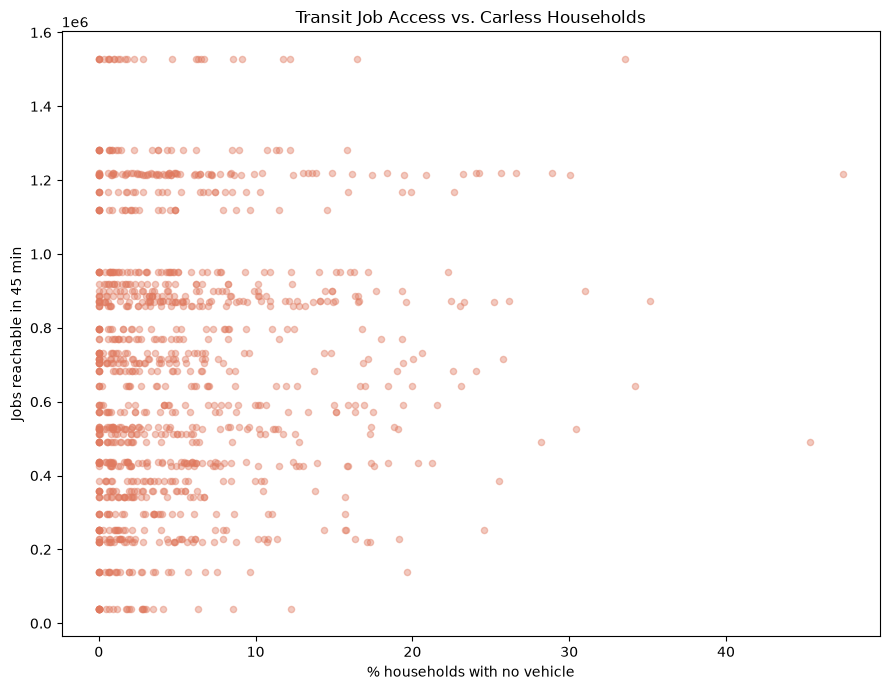

In [22]:
import matplotlib.pyplot as plt

# first merge carless % onto the access data
equity = access_map.merge(vehicles_clean, on="GEOID", how="left")
equity = equity.dropna(subset=["pct_no_vehicle", "jobs_reachable_45min"]).copy()

# carless % vs. job access ----
corr_v = equity["pct_no_vehicle"].corr(equity["jobs_reachable_45min"])
print(f"Correlation (% carless vs. job access): {corr_v:.3f}")
print(f"Tracts analyzed: {len(equity)}")

# plotting scatterplot of % carless households vs. jobs reachable in 45 min
fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(equity["pct_no_vehicle"], equity["jobs_reachable_45min"],
           alpha=0.4, s=20, color="#E07A5F")
ax.set_xlabel("% households with no vehicle")
ax.set_ylabel("Jobs reachable in 45 min")
ax.set_title("Transit Job Access vs. Carless Households")
plt.tight_layout()
plt.savefig("access_vs_vehicles.png", dpi=300, bbox_inches="tight")
plt.show()

In [23]:
# identify "transit desert" tracts: high carless % AND low job access
# thresholds: above-median carless %, below-median access
carless_median = equity["pct_no_vehicle"].median()
access_median = equity["jobs_reachable_45min"].median()

transit_deserts = equity[
    (equity["pct_no_vehicle"] > carless_median) &
    (equity["jobs_reachable_45min"] < access_median)
].copy()

print(f"Transit desert tracts: {len(transit_deserts)}")
print(f"\nThese have above-median carless households AND below-median job access.")
print(f"Avg carless %: {transit_deserts['pct_no_vehicle'].mean():.1f}%")
print(f"Avg jobs reachable: {transit_deserts['jobs_reachable_45min'].mean():,.0f}")

Transit desert tracts: 241

These have above-median carless households AND below-median job access.
Avg carless %: 9.0%
Avg jobs reachable: 419,704


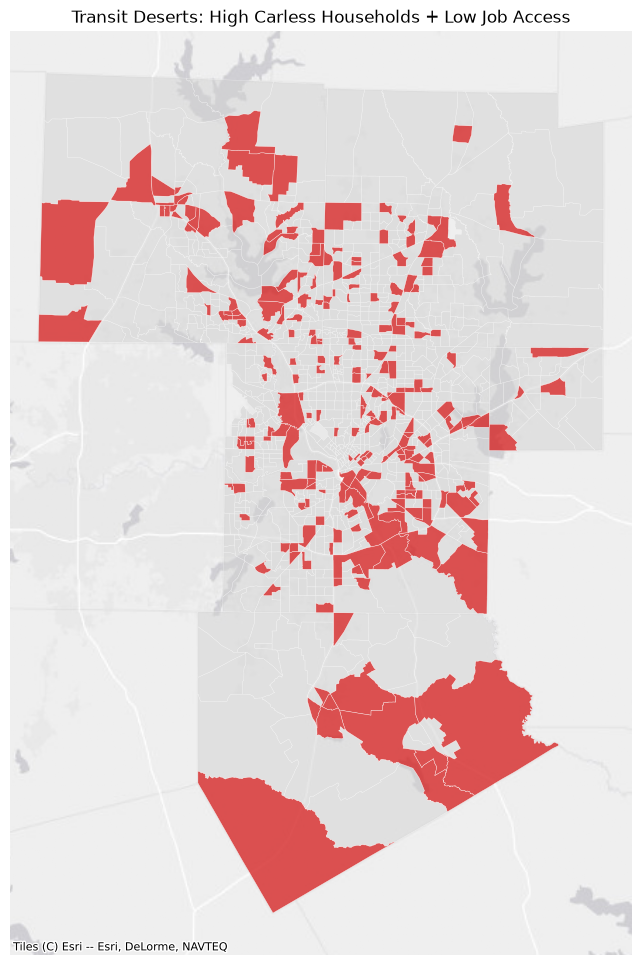

In [24]:
import contextily as cx
import matplotlib.pyplot as plt

# flag transit deserts in the full dataset
equity["is_transit_desert"] = (
    (equity["pct_no_vehicle"] > carless_median) &
    (equity["jobs_reachable_45min"] < access_median)
)

equity_web = equity.to_crs(epsg=3857)

fig, ax = plt.subplots(figsize=(12, 12))
equity_web[~equity_web["is_transit_desert"]].plot(
    ax=ax, color="lightgray", alpha=0.5, edgecolor="white", linewidth=0.3)
equity_web[equity_web["is_transit_desert"]].plot(
    ax=ax, color="#D62828", alpha=0.8, edgecolor="white", linewidth=0.3)
cx.add_basemap(ax, source=cx.providers.Esri.WorldGrayCanvas)
ax.set_title("Transit Deserts: High Carless Households + Low Job Access")
ax.set_axis_off()
plt.savefig("transit_deserts_map.png", dpi=300, bbox_inches="tight")
plt.show()

In [25]:
from shapely.ops import polygonize, unary_union

# The six thresholds in the data
thresholds = [10, 15, 20, 30, 45, 60]

# Build job points once (reused for every threshold)
job_points = centroids.merge(dart[["GEOID", "total_jobs"]], on="GEOID", how="left")

# Store results for each threshold
all_results = {}

for t in thresholds:
    # 1. Filter to this threshold
    iso_t = iso_full[iso_full["minutes"] == float(t)].copy()

    # 2. Fill outlines into polygons
    filled = []
    for idx, row in iso_t.iterrows():
        polys = list(polygonize(row.geometry))
        filled.append(unary_union(polys) if polys else None)
    iso_t["geometry"] = filled
    iso_t = gpd.GeoDataFrame(iso_t[iso_t.geometry.notna()], crs="EPSG:4326")

    # 3. Count reachable jobs
    reachable = gpd.sjoin(job_points, iso_t, how="inner", predicate="within")
    jobs_t = (
        reachable.groupby("GEOID_right")["total_jobs"].sum().reset_index()
        .rename(columns={"GEOID_right": "GEOID", "total_jobs": f"jobs_{t}min"})
    )
    all_results[t] = jobs_t
    print(f"{t} min: done ({len(jobs_t)} tracts, avg {jobs_t[f'jobs_{t}min'].mean():,.0f} jobs)")

print("\nAll thresholds computed!")

10 min: done (1123 tracts, avg 53,481 jobs)
15 min: done (1123 tracts, avg 68,448 jobs)
20 min: done (1123 tracts, avg 96,213 jobs)
30 min: done (1123 tracts, avg 212,838 jobs)
45 min: done (1123 tracts, avg 695,238 jobs)
60 min: done (1123 tracts, avg 1,248,230 jobs)

All thresholds computed!


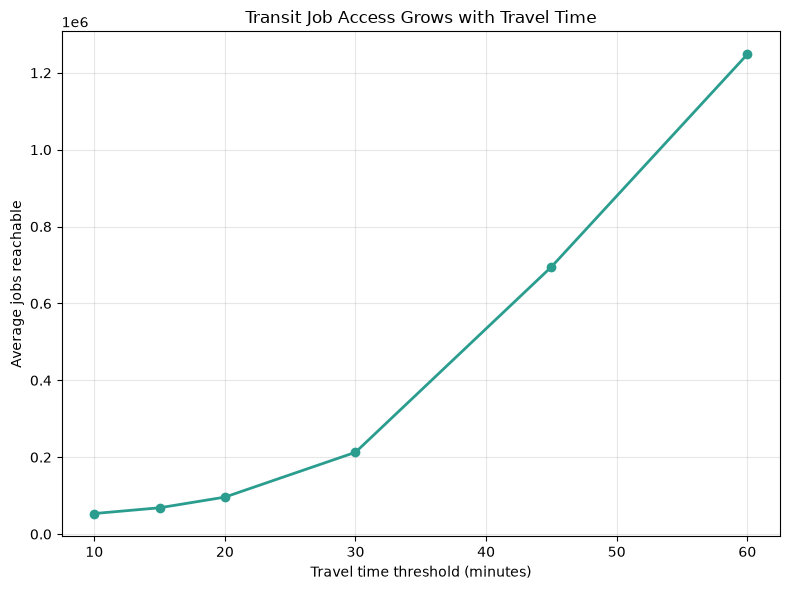

In [26]:
import matplotlib.pyplot as plt

# Merge all six thresholds onto the tract data
access_all = dart.copy()
for t in thresholds:
    access_all = access_all.merge(all_results[t], on="GEOID", how="left")

# Plot the average growth curve
avg_by_threshold = [all_results[t][f"jobs_{t}min"].mean() for t in thresholds]

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(thresholds, avg_by_threshold, marker="o", linewidth=2, color="#2A9D8F")
ax.set_xlabel("Travel time threshold (minutes)")
ax.set_ylabel("Average jobs reachable")
ax.set_title("Transit Job Access Grows with Travel Time")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("access_growth_curve.png", dpi=300, bbox_inches="tight")
plt.show()

In [27]:
import numpy as np
from libpysal.weights import Queen
from esda.moran import Moran, Moran_Local

# data for LISA analysis: tracts with jobs reachable in 45 min
# use the access_map (tracts with jobs_reachable_45min), drop missing values
lisa_data = access_map.dropna(subset=["jobs_reachable_45min"]).copy()
lisa_data = lisa_data.reset_index(drop=True)

# "queen" = tracts are neighbors if they share any border or corner
w = Queen.from_dataframe(lisa_data, use_index=False)
w.transform = "r"   # row-standardize the weights

# global moran's I (is there clustering overall?)
y = lisa_data["jobs_reachable_45min"].values
moran = Moran(y, w)
print(f"Global Moran's I: {moran.I:.3f}")
print(f"p-value: {moran.p_sim:.4f}")

# local moran's I / LISA (where are the clusters?)
lisa = Moran_Local(y, w)

# add cluster categories to the data
# 1=High-High, 2=Low-High, 3=Low-Low, 4=High-Low; significant only
lisa_data["lisa_q"] = lisa.q
lisa_data["lisa_p"] = lisa.p_sim
lisa_data["significant"] = lisa.p_sim

Global Moran's I: 0.364
p-value: 0.0010


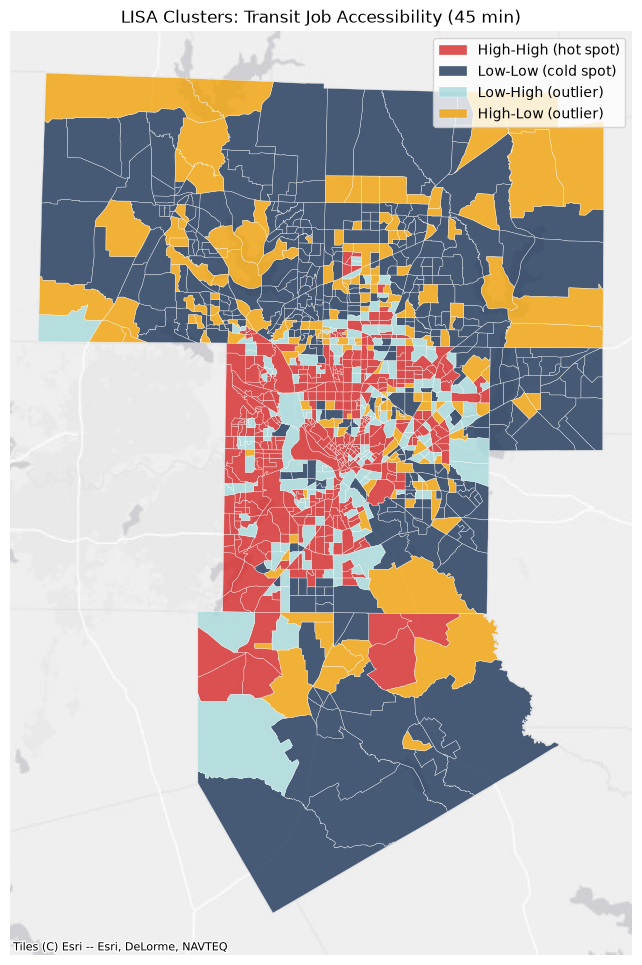

In [28]:
import matplotlib.pyplot as plt
import contextily as cx

# label each significant tract by cluster type
def label_cluster(row):
    if not row["significant"]:
        return "Not significant"
    if row["lisa_q"] == 1:
        return "High-High (hot spot)"
    elif row["lisa_q"] == 3:
        return "Low-Low (cold spot)"
    elif row["lisa_q"] == 2:
        return "Low-High (outlier)"
    elif row["lisa_q"] == 4:
        return "High-Low (outlier)"

lisa_data["cluster"] = lisa_data.apply(label_cluster, axis=1)

# colors for each category
colors = {
    "High-High (hot spot)": "#D62828",   # red = high access cluster
    "Low-Low (cold spot)": "#1D3557",    # dark blue = low access cluster (transit deserts!)
    "Low-High (outlier)": "#A8DADC",
    "High-Low (outlier)": "#F1A208",
    "Not significant": "lightgray",
}

lisa_web = lisa_data.to_crs(epsg=3857)

fig, ax = plt.subplots(figsize=(12, 12))
for cat, color in colors.items():
    subset = lisa_web[lisa_web["cluster"] == cat]
    if len(subset) > 0:
        subset.plot(ax=ax, color=color, label=cat, alpha=0.8,
                    edgecolor="white", linewidth=0.3)

cx.add_basemap(ax, source=cx.providers.Esri.WorldGrayCanvas)
ax.legend(loc="upper right", fontsize=10)
ax.set_title("LISA Clusters: Transit Job Accessibility (45 min)")
ax.set_axis_off()
plt.savefig("lisa_clusters_map.png", dpi=300, bbox_inches="tight")
plt.show()

In [29]:
import numpy as np
from libpysal.weights import Queen
from esda.moran import Moran, Moran_Local

# data for LISA analysis: tracts with jobs reachable in 45 min
# use the access_map (tracts with jobs_reachable_45min), drop missing values
lisa_data = access_map.dropna(subset=["jobs_reachable_45min"]).copy()
lisa_data = lisa_data.reset_index(drop=True)

# "queen" = tracts are neighbors if they share any border or corner
w = Queen.from_dataframe(lisa_data, use_index=False)
w.transform = "r"   # row-standardize the weights

# global moran's I (is there clustering overall?)
y = lisa_data["jobs_reachable_45min"].values
moran = Moran(y, w)
print(f"Global Moran's I: {moran.I:.3f}")
print(f"p-value: {moran.p_sim:.4f}")

# local moran's I / LISA (where are the clusters?)
lisa = Moran_Local(y, w)

# add cluster categories to the data
# 1=High-High, 2=Low-High, 3=Low-Low, 4=High-Low; significant only
lisa_data["lisa_q"] = lisa.q
lisa_data["lisa_p"] = lisa.p_sim
lisa_data["significant"] = lisa.p_sim

Global Moran's I: 0.364
p-value: 0.0010


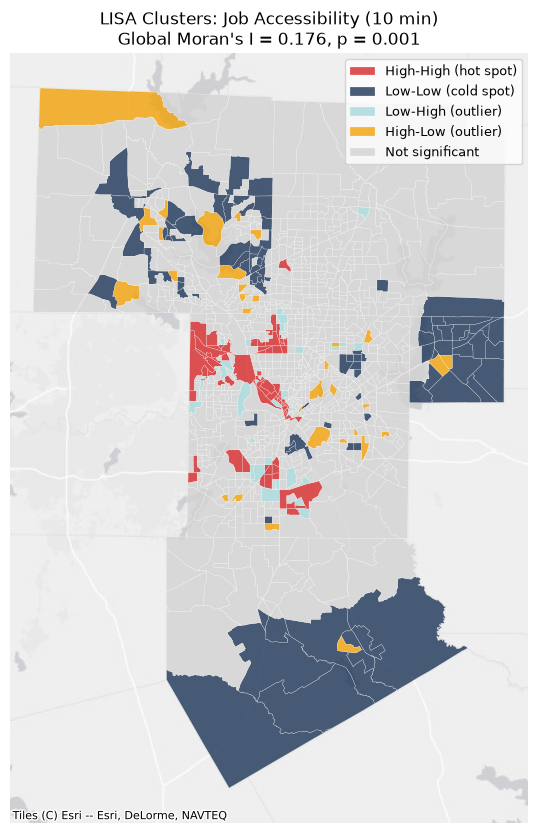

10 min → Moran's I: 0.176, p: 0.001, cold-spot tracts: 95


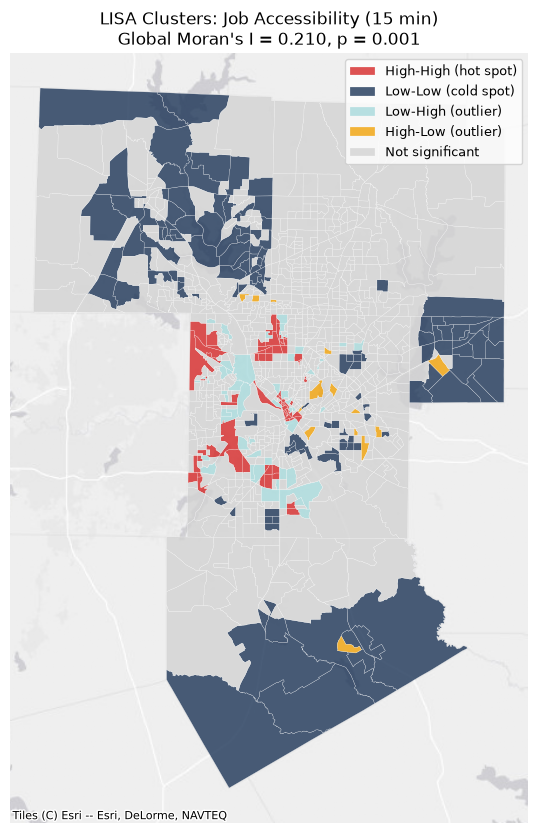

15 min → Moran's I: 0.210, p: 0.001, cold-spot tracts: 133


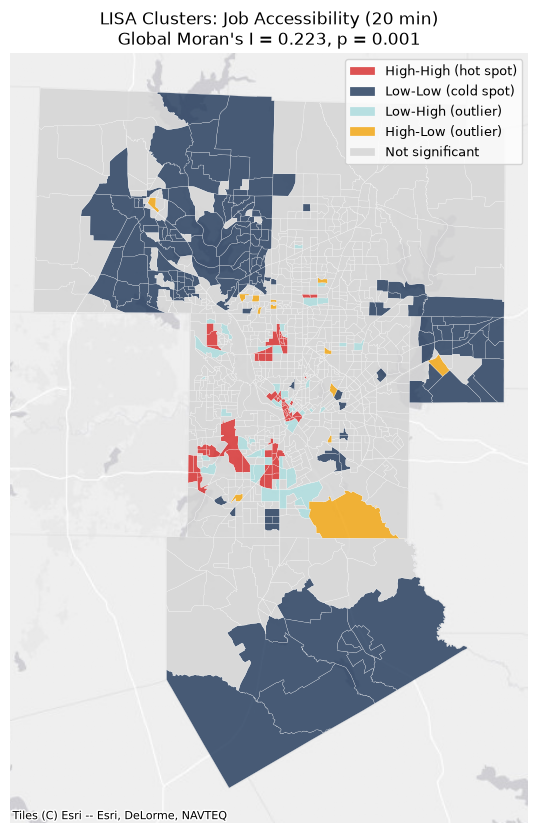

20 min → Moran's I: 0.223, p: 0.001, cold-spot tracts: 163


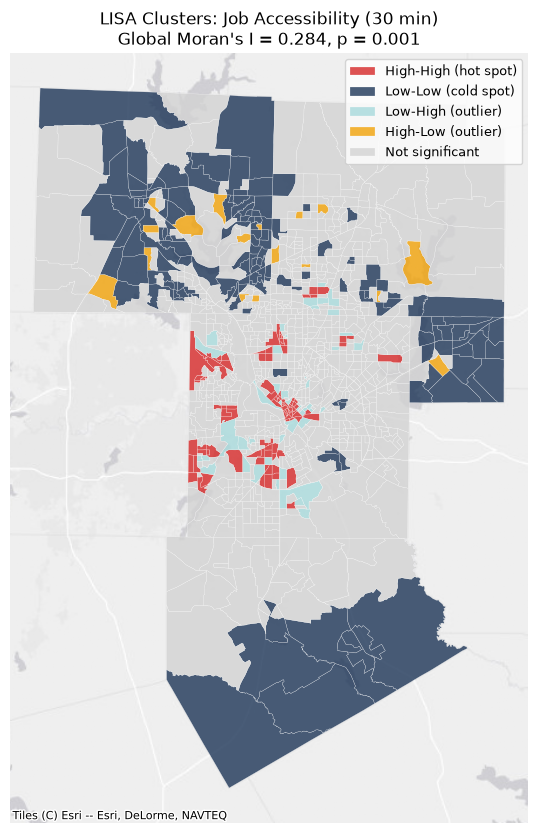

30 min → Moran's I: 0.284, p: 0.001, cold-spot tracts: 154


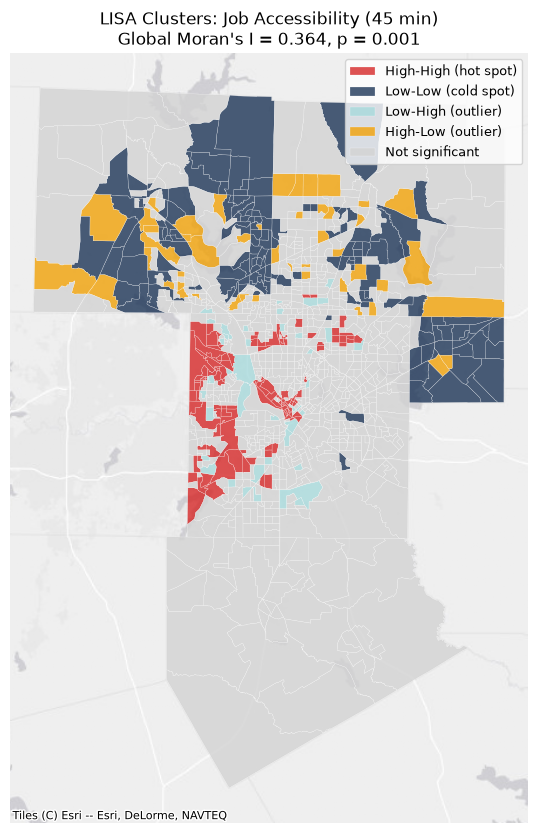

45 min → Moran's I: 0.364, p: 0.001, cold-spot tracts: 149


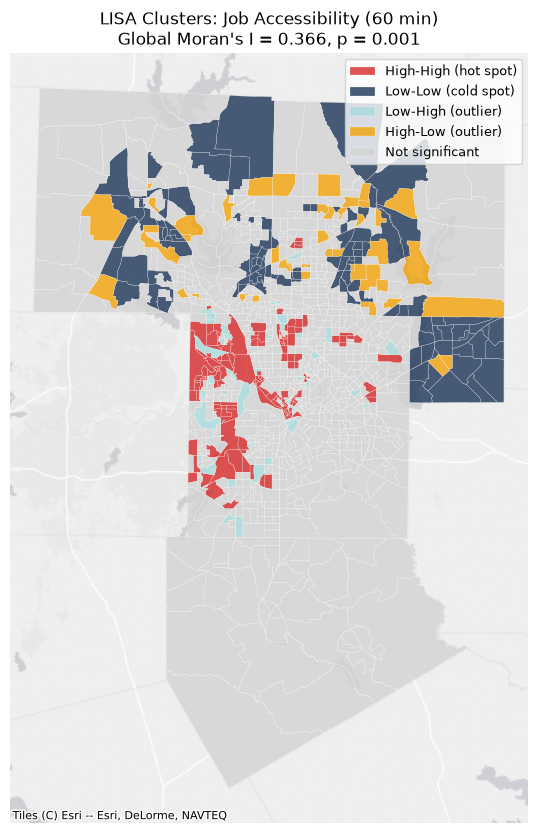

60 min → Moran's I: 0.366, p: 0.001, cold-spot tracts: 113


In [30]:
import matplotlib.pyplot as plt
import contextily as cx
from libpysal.weights import Queen
from esda.moran import Moran, Moran_Local

thresholds = [10, 15, 20, 30, 45, 60]

colors = {
    1: "#D62828",   # High-High (hot spot)
    3: "#1D3557",   # Low-Low (cold spot)
    2: "#A8DADC",   # Low-High (outlier)
    4: "#F1A208",   # High-Low (outlier)
    0: "lightgray", # Not significant
}
labels = {1: "High-High (hot spot)", 3: "Low-Low (cold spot)",
          2: "Low-High (outlier)", 4: "High-Low (outlier)", 0: "Not significant"}

for t in thresholds:
    col = f"jobs_{t}min"
    # Prep data for this threshold
    d = access_all.dropna(subset=[col]).reset_index(drop=True).copy()

    # Spatial weights
    w = Queen.from_dataframe(d, use_index=False)
    w.transform = "r"

    # Global + Local Moran's
    y = d[col].values
    moran = Moran(y, w)
    lisa = Moran_Local(y, w)

    # Assign cluster category (0 if not significant)
    d["cat"] = [q if p < 0.05 else 0 for q, p in zip(lisa.q, lisa.p_sim)]

    # Plot
    d_web = d.to_crs(epsg=3857)
    fig, ax = plt.subplots(figsize=(10, 10))
    for cat, color in colors.items():
        sub = d_web[d_web["cat"] == cat]
        if len(sub) > 0:
            sub.plot(ax=ax, color=color, label=labels[cat], alpha=0.8,
                     edgecolor="white", linewidth=0.2)
    cx.add_basemap(ax, source=cx.providers.Esri.WorldGrayCanvas)
    ax.legend(loc="upper right", fontsize=9)
    ax.set_title(f"LISA Clusters: Job Accessibility ({t} min)\nGlobal Moran's I = {moran.I:.3f}, p = {moran.p_sim:.3f}")
    ax.set_axis_off()
    plt.savefig(f"lisa_{t}min.png", dpi=300, bbox_inches="tight")
    plt.show()

    print(f"{t} min → Moran's I: {moran.I:.3f}, p: {moran.p_sim:.3f}, cold-spot tracts: {(d['cat']==3).sum()}")

In [31]:
import pandas as pd
import geopandas as gpd
from shapely.ops import polygonize, unary_union

def get_accessible_jobs_safe(iso_full, job_points, dart_tracts, threshold):
    """
    Returns ALL tracts with reachable job counts.
    Tracts with no reachable jobs get 0 (not NaN).
    """
    # 1. Filter and fill polygons for this threshold
    iso_t = iso_full[iso_full["minutes"] == float(threshold)].copy()
    
    filled = []
    for geom in iso_t.geometry:
        try:
            polys = list(polygonize(geom))
            filled.append(unary_union(polys) if polys else None)
        except Exception:
            filled.append(None)
            
    iso_t["geometry"] = filled
    iso_t = gpd.GeoDataFrame(iso_t[iso_t.geometry.notna()], crs="EPSG:4326")
    
    # 2. Spatial join to find reachable jobs
    reachable = gpd.sjoin(job_points, iso_t, how="inner", predicate="within")
    jobs_agg = (
        reachable.groupby("GEOID_right")["total_jobs"].sum()
        .reset_index()
        .rename(columns={"GEOID_right": "GEOID", "total_jobs": f"jobs_{threshold}min"})
    )
    
    # 3. LEFT JOIN back to full tract set + FILL NA WITH ZERO
    result = dart_tracts[["GEOID", "geometry"]].merge(jobs_agg, on="GEOID", how="left")
    result[f"jobs_{threshold}min"] = result[f"jobs_{threshold}min"].fillna(0).astype(int)
    
    return result

# Rebuild all thresholds safely
thresholds = [10, 15, 20, 30, 45, 60]
access_all = dart[["GEOID", "geometry", "median_income"]].copy()

print("Computing zero-safe accessibility for all thresholds...")
for t in thresholds:
    safe_result = get_accessible_jobs_safe(iso_full, job_points, dart, t)
    access_all = access_all.merge(safe_result[["GEOID", f"jobs_{t}min"]], on="GEOID", how="left")
    
    zeros = (access_all[f"jobs_{t}min"] == 0).sum()
    print(f"  {t:>2d} min → {zeros:>4d} zero-job tracts ({zeros/len(access_all)*100:.1f}%)")

print(f"\n✓ All {len(access_all)} tracts retained. No NaN values in job columns.")
print(access_all[[f"jobs_{t}min" for t in thresholds]].describe())

Computing zero-safe accessibility for all thresholds...
  10 min →    0 zero-job tracts (0.0%)
  15 min →    0 zero-job tracts (0.0%)
  20 min →    0 zero-job tracts (0.0%)
  30 min →    0 zero-job tracts (0.0%)
  45 min →    0 zero-job tracts (0.0%)
  60 min →    0 zero-job tracts (0.0%)

✓ All 1123 tracts retained. No NaN values in job columns.
          jobs_10min     jobs_15min     jobs_20min     jobs_30min  \
count    1123.000000    1123.000000    1123.000000    1123.000000   
mean    53481.166518   68447.868210   96213.130899  212837.648264   
std     33186.970055   50391.383424   77240.938837  146679.234431   
min      8149.000000   14327.000000   19962.000000   22590.000000   
25%     32739.000000   38791.000000   53147.000000  108096.000000   
50%     44967.000000   53891.000000   66790.000000  186596.000000   
75%     69733.000000   78942.500000  106097.000000  297796.500000   
max    184321.000000  249590.000000  357741.000000  623755.000000   

         jobs_45min    jobs_6

In [32]:
# Show the access disparity that replaces "zero-job" analysis
col = "jobs_45min"
print(f"=== ACCESS DISPARITY AT 45 MINUTES ===")
print(f"Bottom 10%: ≤ {access_all[col].quantile(0.10):,.0f} jobs")
print(f"Bottom 25%: ≤ {access_all[col].quantile(0.25):,.0f} jobs")
print(f"Median:       {access_all[col].median():,.0f} jobs")
print(f"Top 25%:    ≥ {access_all[col].quantile(0.75):,.0f} jobs")
print(f"Top 10%:    ≥ {access_all[col].quantile(0.90):,.0f} jobs")
print(f"\nRatio (90th/10th percentile): "
      f"{access_all[col].quantile(0.90)/access_all[col].quantile(0.10):.1f}x")

=== ACCESS DISPARITY AT 45 MINUTES ===
Bottom 10%: ≤ 252,902 jobs
Bottom 25%: ≤ 433,088 jobs
Median:       704,928 jobs
Top 25%:    ≥ 909,452 jobs
Top 10%:    ≥ 1,215,926 jobs

Ratio (90th/10th percentile): 4.8x
